In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from lightgbm import LGBMClassifier

In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../../Edge-IIoTset_ML-112.csv')

In [4]:
df.head(10)

,arp.opcode,arp.hw.size,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,http.content_length,http.response,tcp.ack,tcp.ack_raw,tcp.checksum,...,dns_4,dns_5,dns_6,dns_7,mqtt1_0,mqtt1_1,mqtt1_2,mqtt2_0,mqtt3_0,mqtt3_2
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,87.0,3.794211e+09,48707.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,59.0,6.828863e+08,19031.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,194.0,2.337571e+09,39685.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,16724.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,6.196863e+08,26682.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6,0.0,0.0,9047.0,41365.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,365851987.0,3.658520e+08,56450.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,261.0,2.367878e+09,44524.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152245 entries, 0 to 152244
Data columns (total 73 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   arp.opcode               152245 non-null  float64
 1   arp.hw.size              152245 non-null  float64
 2   icmp.checksum            152245 non-null  float64
 3   icmp.seq_le              152245 non-null  float64
 4   icmp.transmit_timestamp  152245 non-null  float64
 5   http.content_length      152245 non-null  float64
 6   http.response            152245 non-null  float64
 7   tcp.ack                  152245 non-null  float64
 8   tcp.ack_raw              152245 non-null  float64
 9   tcp.checksum             152245 non-null  float64
 10  tcp.connection.fin       152245 non-null  float64
 11  tcp.connection.rst       152245 non-null  float64
 12  tcp.connection.syn       152245 non-null  float64
 13  tcp.connection.synack    152245 non-null  float64
 14  tcp.

In [6]:
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_TCP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_UDP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_HTTP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_ICMP', 'DDoS')

df['Attack_type'] = df['Attack_type'].str.replace('Port_Scanning', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Fingerprinting', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Vulnerability_scanner', 'Scanning')

df['Attack_type'] = df['Attack_type'].str.replace('MITM', 'MITM')

df['Attack_type'] = df['Attack_type'].str.replace('XSS', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('SQL_injection', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('Uploading', 'Injection')

df['Attack_type'] = df['Attack_type'].str.replace('Backdoor', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Password', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Ransomware', 'Malware')

In [7]:
print(df['Attack_type'].value_counts())

Attack_type
DDoS         48336
Injection    30048
Malware      29526
Normal       24141
Scanning     19836
MITM           358
Name: count, dtype: int64


In [8]:
# Creating a dictionary of Types
attacks = {'Normal':0, 'DDoS':1, 'Scanning':2, 'Injection':3, 'MITM':4, 'Malware':5}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [9]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [10]:
# Apply the Chi-Squared test
chi_selector = SelectKBest(chi2, k='all')  # Set k to the desired number of features
X_kbest = chi_selector.fit_transform(X, y)

In [11]:
# Get the scores for each feature
chi_scores = chi_selector.scores_

# Combine scores with feature names
chi_scores = pd.DataFrame({'feature': X.columns, 'score': chi_scores})

# Sort the features by their scores
chi_scores = chi_scores.sort_values(by='score', ascending=False)

print(chi_scores)

                    feature         score
8               tcp.ack_raw  3.741190e+13
7                   tcp.ack  1.533944e+13
18                  tcp.seq  1.472715e+12
4   icmp.transmit_timestamp  4.262691e+10
20               udp.stream  4.109097e+10
..                      ...           ...
43                  http1_3  6.675187e+00
53                  http3_4  6.675187e+00
49                  http3_0  6.675187e+00
64                    dns_7  5.306491e+00
25   dns.retransmit_request  5.306491e+00

[71 rows x 2 columns]


/tmp/ipykernel_568291/4000908500.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')


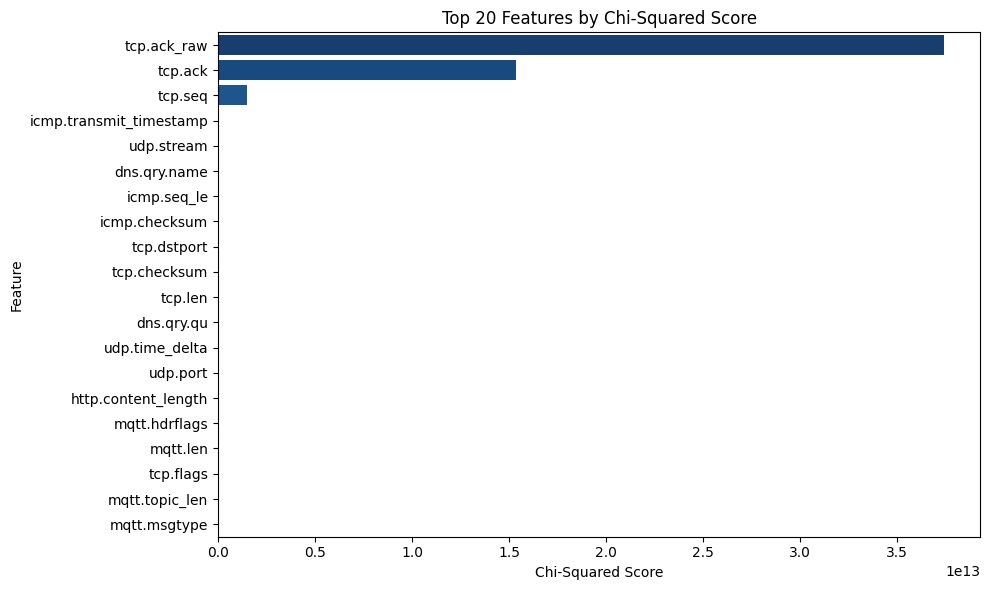

In [12]:
chi_scores_top = chi_scores.head(20)
plt.figure(figsize=(10, 6))
sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')
plt.title(f"Top 20 Features by Chi-Squared Score")
plt.xlabel("Chi-Squared Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

/tmp/ipykernel_568291/496316430.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')


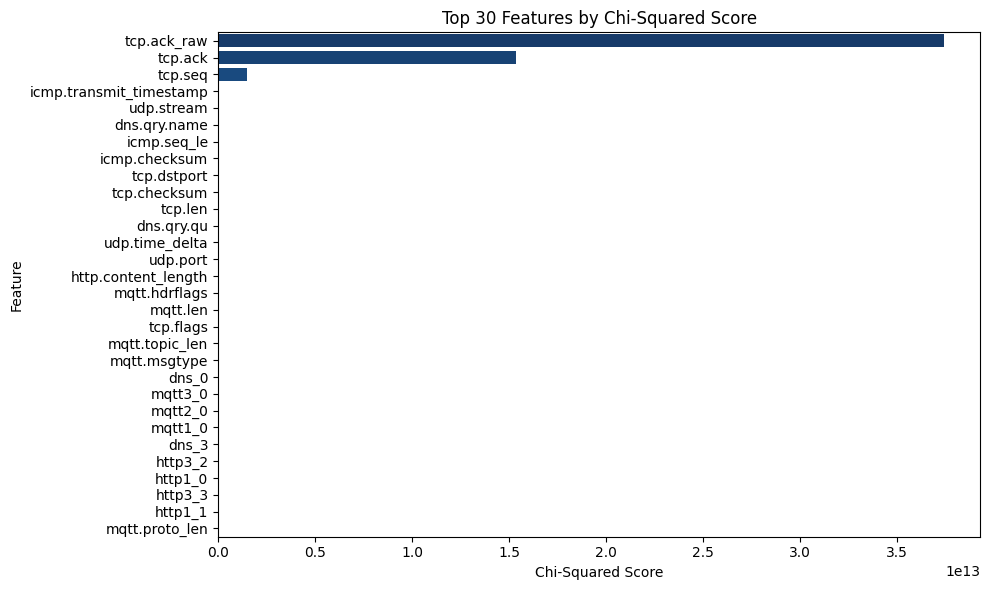

In [13]:
chi_scores_top = chi_scores.head(30)
plt.figure(figsize=(10, 6))
sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')
plt.title(f"Top 30 Features by Chi-Squared Score")
plt.xlabel("Chi-Squared Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

/tmp/ipykernel_568291/2188580838.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')


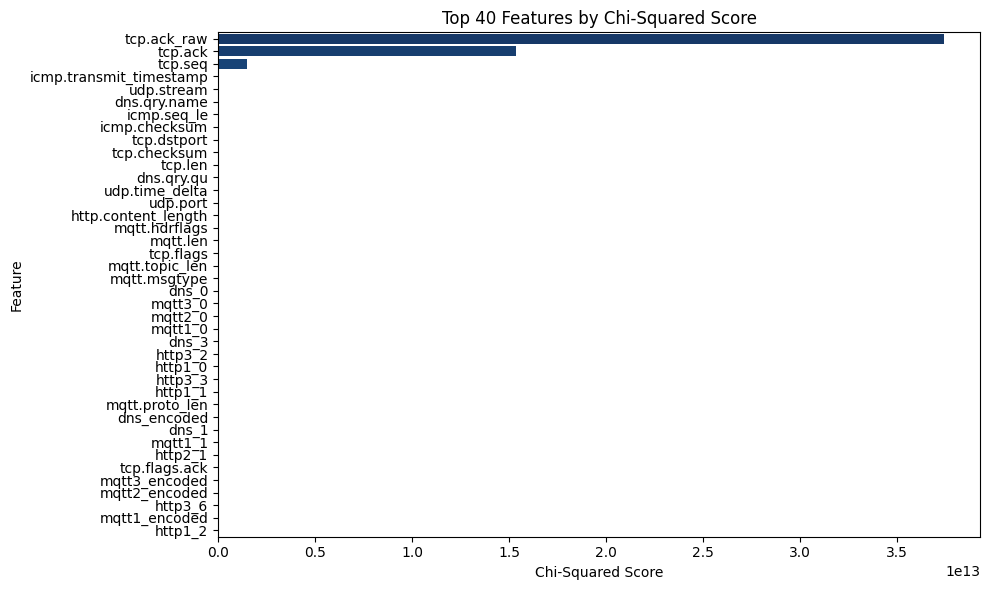

In [14]:
chi_scores_top = chi_scores.head(40)
plt.figure(figsize=(10, 6))
sns.barplot(data=chi_scores_top, x='score', y='feature', palette='Blues_r')
plt.title(f"Top 40 Features by Chi-Squared Score")
plt.xlabel("Chi-Squared Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [15]:
# Initialize the LightGBM classifier
def light_gbm_model():
    _model = LGBMClassifier(
        objective='multiclass',
        num_class=6,
        learning_rate=0.1,
        n_estimators=100,
        num_leaves=31,
        max_depth=-1,
        reg_alpha=0,
        reg_lambda=0.5,
        random_state=42
    )
    return _model

In [16]:
max_features = len(chi_scores['feature'].tolist())
feature_counts = list(range(10, max_features + 1, 10))  # e.g., 10, 20, ..., up to all features

results = []
num_classes = 6
for k in feature_counts:
    selected_features = chi_scores['feature'].tolist()[:k]

    X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.125, random_state=42)

    scaler = StandardScaler().fit(X_train)
    X_train = scaler.transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)

    model = light_gbm_model()

    model.fit(X_train, y_train,
              eval_set=(X_val, y_val),
              eval_names=['val'],
              eval_metric=['multi_logloss', 'multi_error']
              )

    evals_result = model.evals_result_
    val_errors = evals_result['val']['multi_error']
    best_iter = val_errors.index(min(val_errors))
    val_accuracy = 1 - val_errors[best_iter]

    results.append((k, val_accuracy))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002340 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2316
[LightGBM] [Info] Number of data points in the train set: 106571, number of used features: 10
[LightGBM] [Info] Start training from score -1.842267
[LightGBM] [Info] Start training from score -1.145780
[LightGBM] [Info] Start training from score -2.038795
[LightGBM] [Info] Start training from score -1.618828
[LightGBM] [Info] Start training from score -6.055106
[LightGBM] [Info] Start training from score -1.645561
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] N

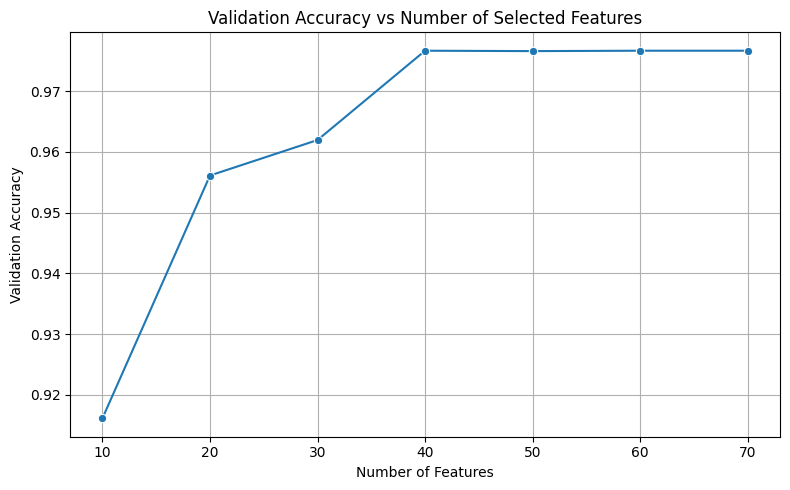

In [17]:
results_df = pd.DataFrame(results, columns=['num_features', 'val_accuracy'])
plt.figure(figsize=(8,5))
sns.lineplot(data=results_df, x='num_features', y='val_accuracy', marker='o')
plt.title("Validation Accuracy vs Number of Selected Features")
plt.xlabel("Number of Features")
plt.ylabel("Validation Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:
results_df

,num_features,val_accuracy
0,10,0.916125
1,20,0.956125
2,30,0.961970
3,40,0.976683
4,50,0.976617
5,60,0.976683
6,70,0.976683


In [19]:
# Convert to list of dicts
results_dict = results_df.to_dict(orient='records')

# Save to local hard drive (same folder as script, or change path as needed)
output_path = 'results/FI/results_chi_tuning.json'

with open(output_path, 'w') as f:
    json.dump(results_dict, f, indent=4)